### Simple environment
using random jamming, single action instead of dual for simplicity (1 action , identified by freq * power)


In [1]:
import gymnasium as gym
import numpy as np
import random as random
from gymnasium import spaces
from gymnasium.envs.registration import register     #name the env
from gymnasium.utils.env_checker import check_env   #check if the env follows the gym API
import matplotlib.pyplot as plt
from IPython.display import display
import time

#make the name of the env
register(
    id='AntiJammingEnv-v0',                         #name of the env when we instatiate
    # entry_point="simplenv.ipynb:AntiJammingEnv",   #module name:class name
    entry_point= lambda **kwargs: AntiJammingEnv(**kwargs),  #if the class is in the same file, we can use lambda
)


class AntiJammingEnv(gym.Env):
    # used to render the env
    metadata = {"render_modes": ["human"], "render_fps": 4}


    def __init__(self, num_freqs=22, num_powers=50, num_of_jammers=7, jammer_type="sweeping", render_mode=None):
        super().__init__()
        self.num_freqs = num_freqs
        self.num_powers = num_powers
        self.jammer_type = jammer_type          #random in this env
        self.num_of_jammers = num_of_jammers    # 7 random jammers
        self._sweep_step = 1             # how many bins to move per step for sweeping jammer
        self.power_levels = np.linspace(1.58e-4, 1e-3, num_powers)  # power levels from -8dbm to 0dbm converted to watts , taken from the paper (50 levels)
        self.jammer_power = 3.162e-3 # Jammer power 3.162e-3 W = 5 dBm from Table 1 in the paper

        #modifications to state
        self.state = None                 # current observation (PSD vector)
        self.state_dim = num_freqs + 1  #PSD + prev_freq 
        self.prev_freq = None           #need for freq switching penalty
        # self.prev_crc = None            #new

        # moved from step() to be class variables
        self.power_noise  = 3.162e-16      # NEW (kTB*N; matches your comment)
        self.alpha_k_user   = 9.1e-12        # NEW (Rayleigh scale for user)
        self.alpha_k_jammer = 1.15e-12       # NEW (Rayleigh scale for jammer)
        # self.fail_penalty = 0.3            # NEW (penalize CRC failure so staying jammed < 0)
        self._gain_user   = np.zeros(self.num_freqs)   # NEW (slot user gains)
        self._gain_jammer = np.zeros(self.num_freqs)   # NEW (slot jammer gains)


        #all rendering related variables
        self.render_mode = render_mode
        self._fig = None
        self._ax = None
        self._jam_bars = None
        self._agent_line = None
        self._power_text = None
        self._last_action = None
        self._last_reward = None
        self._total_reward = 0.0
        self.agent_marker = None
        self._display_handle = None
        self._max_steps = 200
        self._step_count = 0
        self._switching_count = 0

        # Define action space (freq × power combinations)
        # 22 * 50 = 1100 discrete actions (0..1099)
        # too many actions for DQN, but OK for policy gradient methods
        self.action_space = spaces.Discrete(num_freqs * num_powers) # run this with DQN cuz it doens't take multi-discrete
        # self.action_space = spaces.MultiDiscrete([self.num_freqs, self.num_powers]) # run this with ppo

        # State = PSD (vector of size num_freqs)
        self.observation_space = spaces.Box(
            low=0.0, high=1.0, shape=(self.state_dim,), dtype=np.float32
        )

        #self.rng = random number generator
        self.rng = np.random.default_rng()

        # Internal jammer state & dynamics parameters
        self._jam_idxs = []             # indices of the currently jammed frequency bins


    def _build_state_from_jammer(self):
        """
        Construct the PSD observation vector given the *current* jammers indecies.
        - Background noise self.power_noise (kTB*NF from paper, e-16 range) plus 5% gaussian noise
        - Min max scaling to fit in state space (0..1)

        This function is used in both `reset()` and `step()` so that
        the observation is always generated consistently.
        """

        s = np.full(self.num_freqs, self.power_noise)   # background noise = power noise (kTBN)

        if len(self._jam_idxs) == 0:       # choose jammer indices if not already chosen
            self._jam_idxs = self.np_random.choice(range(self.num_freqs), size=self.num_of_jammers, replace=False).tolist()

        # set jammer powers
        jam_idxs_array = np.array(self._jam_idxs, dtype=int)  # helper array to avoid for loop to set each jammer power
        s[jam_idxs_array] += self.jammer_power * self._gain_jammer[jam_idxs_array] # psd = jammer power + noise

        #add gaussian noise to the psd
        s = s * (1.0 + 0.05 * self.np_random.standard_normal(self.num_freqs))  # since power Noise is constant, Add ~5% Gaussian “measurement noise” (AGC jitter, PSD estimator variance, etc)
        s = np.clip(s, self.power_noise * 0.5, None)    # (clip at 0.5*powerNoise to avoid negative watt values of PSD)

        #normalize the state, smoother learning. this is minMax scaling (min 0, max 1, to fit in state)
# FIXED scaling (stationary across steps)
        # ~95% jammed values lie within headroom when gains are exponential
        headroom = self.jammer_power * self.alpha_k_jammer * 2.5
        denom = max(headroom, 1e-30)
        s_normalized = (s - self.power_noise) / denom
        s_normalized = np.clip(s_normalized,0.0,1.0)

        #add prev_freq and prev_crc to the state
        prev_f_norm = 0.0 if self.prev_freq is None else self.prev_freq / (self.num_freqs - 1)
        full_state  = np.concatenate([s_normalized, [prev_f_norm]], axis=0)


        return full_state.astype(np.float32)



    def _advance_jammer(self):
        """
        Update the jammer index based on jammer_type dynamics:
        - fixed: jammer never moves
        - sweeping: jammer shifts to the next bin each step
        - random: jammer picks a new random bin every step
        """

        jt = self.jammer_type.lower()
        if jt == "fixed":
            pass  # jammer stays in the same bin forever

        elif jt == "sweeping":
            for i in range(len(self._jam_idxs)):
                #modulo to wrap around (23 -> 1 for example)
                self._jam_idxs[i] = (self._jam_idxs[i] + self._sweep_step) % self.num_freqs

        elif jt == "random":
            # for i in range(len(self._jam_idxs)):
            #     self._jam_idxs[i] = int(self.rng.integers(0, self.num_freqs)) May lead to duplicates
            self._jam_idxs = self.np_random.choice(self.num_freqs, size=self.num_of_jammers, replace=False).tolist()  # NEW



    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)

        # Initialize jammer index and build the first observation
        # used self.np_random that apparently got initted by super().reset(seed=seed)

        #new reset function
        self._jam_idxs = self.np_random.choice(self.num_freqs, size=self.num_of_jammers, replace=False).tolist()
        U = self.np_random.random(self.num_freqs)
        U = np.clip(U, 1e-9, 1.0)   # ensures U never hits 0 → no log(0)
        J = self.np_random.random(self.num_freqs)
        J = np.clip(J, 1e-9, 1.0)   # ensures U never hits 0 → no log(0)
        self._gain_user = self.alpha_k_user * (-np.log(U))
        self._gain_jammer = self.alpha_k_jammer * (-np.log(J)) #

        self.prev_freq = None
        self._step_count = 0
        self._total_reward = 0.0
        self._switching_count = 0
        self.prev_crc  = 0.0
        self.state = self._build_state_from_jammer()

        info = {}

        #rendering related book-keeping
        self._last_state = self.state      # so first render works
        self._last_action = None
        self._last_reward = None

        return self.state.astype(np.float32), info




    def step(self, action):
        """
        One-slot delay logic:
        - Agent picked `action` using observation s_k (= self._last_state).
        - Environment first advances jammer to unseen slot k+1 and measures s_{k+1}.
        - Reward is computed against s_{k+1} (the actual slot you just transmitted in).
        - Next observation returned to agent is s_{k+1}.
        """
        # Decode (freq, power)
        self._step_count += 1
        freq = action // self.num_powers
        power = action % self.num_powers   # 1..num_powers
        # freq, power = map(int, action)  #power here is the index of the power level
        power = self.power_levels[power]

        # U = self.np_random.random(self.num_freqs)
        # U = np.clip(U, 1e-9, 1.0)   # ensures U never hits 0 → no log(0)
        # J = self.np_random.random(self.num_freqs)
        # J = np.clip(J, 1e-9, 1.0)   # ensures U never hits 0 → no log(0)
        # self._gain_user = self.alpha_k_user * (-np.log(U))
        # self._gain_jammer = self.alpha_k_jammer * (-np.log(J)) #

        # gain_vector_user = self._gain_user # channel gain vector for all frequencies sampled each step
        
        # gain_vector_jammer = self._gain_jammer # channel gain vector for all frequencies sampled each step
        
        
        # rician distribution sampling for gains
        K_dB  = 10.0
        K     = 10 ** (K_dB / 10)
        sigma = 1.0 / np.sqrt(2 * (K + 1))
        los   = np.sqrt(K / (K + 1))    # line of sight component
        n_re  = self.rng.normal(scale=sigma, size=self.num_freqs)   # real part of the complex normal distribution
        n_im  = self.rng.normal(scale=sigma, size=self.num_freqs)   # imaginary part of the complex normal distribution
        power_sample = (los + n_re)**2 + n_im**2          # |h|², 𝔼{power}=1, power is square of amplitude, mean will be 1
        self._gain_user   = self.alpha_k_user   * power_sample
        self._gain_jammer = self.alpha_k_jammer * power_sample.copy()
        gain_vector_user   = self._gain_user   # channel gain vector for all frequencies sampled each step
        gain_vector_jammer = self._gain_jammer # channel gain vector for all frequencies sampled


        # === Move to *new* (unseen) slot and measure PSD_{k+1} ===
        #uncomment this 2 lines for 1slot delay
     

        #uncomment this line for 0slot delay
        curr_psd = self.state  # s_{k}

        # --- Compute reward using the *current* slot conditions (which were not observed before acting) ---
        jammed = (freq in self._jam_idxs)  # NEW
        powerNoise = self.power_noise     # NEW
        jamming_power = self.jammer_power * gain_vector_jammer[freq] if jammed else 0.0 # if jammer is present, its power is 3.162e-3 W (5 dBm) * gain of jammer as in the paper, else very small power 1e-10 W
        sinr = (power*gain_vector_user[freq]) / (powerNoise+jamming_power+1e-30)

        #crc calculation
        beta_th = 10**(8/10)  # SINR threshold for successful CRC, it is taken from GPT as a standard practice with QPSK modulation, but can be manipulated between 6-10 dbm , this shows 8dbm
        crc_success = 1.0 if sinr > beta_th else 0.0

        # Switching penalty (compare with last used freq)
        switching_penalty = 0.0
        if self.prev_freq is not None and self.prev_freq != freq:
            switching_penalty = 1.0
            self._switching_count += 1


        subBandWidth = 25e3 # 25 kHz , taking from the paper that the base is 20 kHz and some roll-off margin
        epsilon = 1.5e9 # scaling the reward function in [-1,1]
        alpha = 0.15 # weight for switching penalty, chosen so swithcing while succesding has good reward but not as good as without swithcing and not as bad as hitting a jammed bin.
        #reward =  (crc_success * (subBandWidth * np.log2(1 + sinr)) / (epsilon * power + 1e-30)) - (alpha * switching_penalty)
        reward = crc_success * (((subBandWidth * np.log2(1+(power/powerNoise)))/(epsilon*power))-alpha*switching_penalty)
        
        # === One-slot-delay book-keeping ===
        # Next observation is the PSD we just measured in this slot.

        #uncomment this for 1slot delay
        self._advance_jammer()
        new_state = self._build_state_from_jammer()    # s_{k+1}
        self._last_state = curr_psd      # used for rendering
        self.state = new_state
        self.prev_freq = freq

        terminated = False
        truncated = self._step_count >= self._max_steps
        info = {"crc_success": crc_success , "jammed_chosen": jammed, "sinr": sinr, "switched": switching_penalty>0, "switching_count": self._switching_count,"power_w": float(power)}
        #rendering related book-keeping
        self._last_action = (freq, power)
        self._last_reward = float(reward)
        self._total_reward = self._total_reward + reward
        if self.render_mode == "human":
            self.render()

        return self.state.astype(np.float32), reward, terminated, truncated, info


    def render(self):
        if self.render_mode != "human":
            return

        # ── show the PSD from the slot where the last action was used ────────────
        psd_to_show = self._last_state[:self.num_freqs] if getattr(self, "_last_state", None) is not None else self.state[:self.num_freqs]
        # ─────────────────────────────────────────────────────────────────────────

        # Lazily build the figure once
        if self._fig is None or not plt.fignum_exists(self._fig.number):
            plt.ioff()
            self._fig, self._ax = plt.subplots(figsize=(10, 4))
            self._ax.set_title("Anti-jamming spectrum (live)")
            self._ax.set_xlabel("Frequency bin")
            self._ax.set_ylabel("PSD / jammer power")
            self._ax.set_ylim(0.0, 1.2)
            self._ax.set_xlim(-0.5, self.num_freqs - 0.5)

            self._jam_bars = self._ax.bar(
                range(self.num_freqs),
                psd_to_show if psd_to_show is not None else np.zeros(self.num_freqs),
                color="#1f77b4",
                alpha=0.75,
            )
            self._agent_marker = self._ax.scatter(
                [], [], s=120, color="#ff7f0e", edgecolor="black", zorder=5
            )
            self._power_text = self._ax.text(
                0.01, 0.97, "Awaiting first action",
                transform=self._ax.transAxes,
                fontsize=11, va="top",
                bbox=dict(boxstyle="round", facecolor="white", alpha=0.85),
            )
            self._fig.canvas.draw()
            self._display_handle = display(self._fig, display_id=True)

        # ── update jammer bars ────────────────────────────────────────────────────
        if psd_to_show is not None:
            for bar, height in zip(self._jam_bars, psd_to_show):
                bar.set_height(height)
                bar.set_color("#d62728" if height > 0.9 else "#1f77b4")

        # ── update agent marker & annotation ──────────────────────────────────────
        if self._last_action is not None:
            freq, power_w = self._last_action
            self._agent_marker.set_offsets([[freq, psd_to_show[freq]]])

            lines = [
                f"Agent freq = {freq}",
                f"Power = {power_w:.2e} W",
            ]
            if self._last_reward is not None:
                lines.append(f"Reward = {self._last_reward:.3f}")
            if self._total_reward is not None:
                lines.append(f"Total = {self._total_reward:.3f}")

            self._power_text.set_text("\n".join(lines))
        else:
            self._agent_marker.set_offsets([])
            self._power_text.set_text("Awaiting first action")

        # ── draw & throttle frame rate ────────────────────────────────────────────
        self._fig.canvas.draw()
        if self._display_handle is not None:
            self._display_handle.update(self._fig)
            time.sleep(0.8)


### ONLY FOR PLOTTING THE REWARD FUNCTION FULLY ###

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# =========================
# Config (aligns with your env)
# =========================
B = 25e3                          # Hz (bandwidth)
epsilon = 9e8                   # energy scaling
beta_th = 10**(6/10)              # CRC threshold (8 dB, linear)
noise_power = 3.162e-16           # W (kTB * NF for 25 kHz, NF=5 dB)
jammer_power = 3.162e-3           # W (5 dBm)
alpha_k_user   = 9.1e-12          # mean user gain (calibrated)
alpha_k_jammer = 1.15e-12         # mean jammer gain (calibrated)

# Sweep ranges (ascending as requested)
freqs = np.arange(1, 23)                      # 1..22
powers_dbm = np.linspace(-8, 0, 50)           # dBm, ascending
powers_w = 1e-3 * 10**(powers_dbm / 10.0)     # W, ascending

rng = np.random.default_rng(123)

# =========================
# Reward definition (no switch penalty here to show the surface cleanly)
# r = phi * (B * log2(1 + SINR) / (epsilon * P))
# SINR = (P * g_user) / (noise_power + I_jam)
# =========================
def reward_single(power_w, jammed, g_user, g_jam):
    I_jam = jammer_power * g_jam if jammed else 0.0
    sinr = (power_w * g_user) / (noise_power + I_jam)
    phi = 1.0 if sinr > beta_th else 0.0
    throughput = B * np.log(1.0 + sinr)
    return phi*((25e3 * np.log(1+sinr))/1e5)


def sample_gain_user():
    return rng.exponential(scale=alpha_k_user)

def sample_gain_jam():
    return rng.exponential(scale=alpha_k_jammer)

# =========================
# Plot 1: Reward vs Power (for multiple freqs) — clean and jammed
# =========================
def plot_reward_vs_power(selected_freqs=(1,5,10,15,20,22), jammed=False, title_suffix=""):
    plt.figure(figsize=(8, 6))
    for f in selected_freqs:
        # Fix gains per curve to avoid noisy wiggles across the sweep
        g_u = sample_gain_user()
        g_j = sample_gain_jam()
        rewards = [reward_single(pw, jammed, g_u, g_j) for pw in powers_w]
        plt.plot(powers_dbm, rewards, label=f"Freq {f} {(g_u/g_j):.2e}")
    plt.xlabel("Power (dBm)")                    # −8 → 0 (ascending)
    plt.ylabel("Reward (no switch)")
    plt.title(f"Reward vs Power {title_suffix}".strip())
    plt.grid(True)
    plt.legend()
    plt.show()

# =========================
# Plot 2: Reward vs Frequency (for multiple powers) — clean and jammed
# =========================
def plot_reward_vs_frequency(selected_p_dbm=(-8, -6, -4, -2, 0), jammed=False, title_suffix=""):
    plt.figure(figsize=(8, 6))
    for p_dbm in selected_p_dbm:
        p_w = 1e-3 * 10**(p_dbm / 10.0)
        # New gains per-frequency to reflect independent fading across bins
        rewards = []
        for _ in freqs:  # 1 → 22 (ascending)
            g_u = sample_gain_user()
            g_j = sample_gain_jam()
            rewards.append(reward_single(p_w, jammed, g_u, g_j))
        plt.plot(freqs, rewards, label=f"P={p_dbm} dBm")
    plt.xlabel("Frequency bin (1 → 22)")
    plt.ylabel("Reward (no switch)")
    plt.title(f"Reward vs Frequency {title_suffix}".strip())
    plt.grid(True)
    plt.legend()
    plt.show()

# =========================
# Usage examples (uncomment the ones you want)
# =========================
plot_reward_vs_power(jammed=False, title_suffix="(Clean bins)")
plot_reward_vs_power(jammed=True,  title_suffix="(Jammed bins)")
plot_reward_vs_frequency(jammed=False, title_suffix="(Clean bins)")
plot_reward_vs_frequency(jammed=True,  title_suffix="(Jammed bins)")


### Check random policy for a few episodes


In [ ]:
import gymnasium as gym

num_episodes = 1
max_steps = 1000
cumulative_reward_over_episodes = 0.0


env = gym.make("AntiJammingEnv-v0", render_mode="human")
env = gym.wrappers.TimeLimit(env, max_episode_steps=max_steps)
base_env = env.unwrapped


for ep in range(num_episodes):
    obs, info = env.reset()
    total_reward = 0.0

    for step in range(max_steps):
        action = env.action_space.sample()
        obs, reward, terminated, truncated, info = env.step(action)

        total_reward += reward

        if terminated or truncated:
            break

    print(f"Episode {ep+1}: return={total_reward:.2f}, steps={step+1}")
    cumulative_reward_over_episodes += total_reward


print(f"Mean reward over episodes: {cumulative_reward_over_episodes / num_episodes:.2f}")
env.close()

## create a greedy policy (no RL in greedy, just to see if RL works)
decode action is a helper function to return freq and power from single action space of freq * power

In [ ]:

def greedy_policy(obs, env, snr_thresh=1.5):

    """Pick the lowest-noise frequency and the smallest power that clears the SNR threshold.

    Args:
        obs: 1-D array of PSD values for each frequency bin (current observation).
        env: Environment instance that exposes `num_powers` and `power_levels`.
        snr_thresh: Minimum SNR required to transmit.

    Returns:
        Encoded action index corresponding to the chosen (frequency, power) pair.
    """

    f = int(np.argmin(obs))
    for idx, power in enumerate(env.power_levels):
        snr = power / (float(obs[f]) + 1e-6)
        if snr > snr_thresh:
            return f * env.num_powers + idx

    return f * env.num_powers + (env.num_powers - 1)


### Check greedy policy for few episodes

In [ ]:
import gymnasium as gym

num_episodes = 10
max_steps = 20
cumulative_reward_over_episodes = 0.0


env = gym.make("AntiJammingEnv-v0", render_mode="human")
env = gym.wrappers.TimeLimit(env, max_episode_steps=max_steps)
base_env = env.unwrapped


for ep in range(num_episodes):
    obs, info = env.reset()
    total_reward = 0.0

    for step in range(max_steps):
        action = greedy_policy(obs, base_env)
        obs, reward, terminated, truncated, info = env.step(action)

        total_reward += reward

        if terminated or truncated:
            break

    print(f"Episode {ep+1}: return={total_reward:.2f}, steps={step+1}")
    cumulative_reward_over_episodes += total_reward


print(f"Mean reward over episodes: {cumulative_reward_over_episodes / num_episodes:.2f}")
env.close()


In [ ]:
import numpy as np

def decode_action(a, env):
    freq = a // env.num_powers
    idx = a % env.num_powers
    return freq, idx, env.power_levels[idx]



In [ ]:
!pip install uv
!uv pip install stable_baselines3 --system

***metric callbacks custion from ammar***

In [2]:
from stable_baselines3.common.callbacks import BaseCallback
import numpy as np

class MetricsCallback(BaseCallback):
    """
    Logs switch-rate, CRC success, and mean power to TensorBoard.
    """
    def __init__(self, log_every=1000):
        super().__init__(verbose=0)
        self.log_every = log_every
        self._reset_acc()

    def _reset_acc(self):
        self.n_steps = 0
        self.n_switch = 0
        self.n_crc = 0
        self.sum_power = 0.0

    def _on_step(self) -> bool:
        # "infos" is a list (one per parallel env)
        for info in self.locals["infos"]:
            self.n_steps   += 1
            self.n_switch  += info.get("switched", 0.0)
            self.n_crc     += info.get("crc_success", 0.0)
            self.sum_power += info.get("power_w", 0.0)

        # flush to TensorBoard every log_every env steps
        if self.n_calls % self.log_every == 0 and self.n_steps > 0:
            self.logger.record("custom/switch_rate",
                               self.n_switch / self.n_steps)
            self.logger.record("custom/crc_success",
                               self.n_crc / self.n_steps)
            self.logger.record("custom/mean_power",
                               self.sum_power / self.n_steps)
            self.logger.dump(self.n_calls)      # push to TB
            self._reset_acc()
        return True

### instantiate env and agent (DQN) to learn


In [3]:
import os
import random
import numpy as np
import gymnasium as gym
from stable_baselines3 import DQN
from stable_baselines3.common.vec_env import DummyVecEnv, VecMonitor
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import EvalCallback
#rewards def:
#reward1 = 0 if jammed else 1
#reward2 = 1.0 if not jammed and no switch else 0.51 if not jammed and switch else 0.0 if jammed and no switch else -0.49
#reward3 = 1 if crc_success == 1.0 else 0
#reward4 = subBandWidth * np.log(1+sinr)/1e5 -for scaling-
def make_env(seed, name):
    def _init():
        env = gym.make("AntiJammingEnv-v0", render_mode=None)
        env.reset(seed=seed)
        env = Monitor(env,
                      filename=os.path.join(f"logs/anti_jam_dqn_{name}_seed{seed}", "monitor.csv"),
                      allow_early_resets=True)
        env = gym.wrappers.TimeLimit(env, max_episode_steps=200)
        return env
    return _init

seeds = [0,1,2,3,4,5]   # run 10 seeds
results = {}  # dict to store per‐seed result history

for seed in seeds:
    name = "reward_paper"  # name of the experiment
    # Set seeds for reproducibility
    random.seed(seed)
    np.random.seed(seed)
    # Env creation
    vec_env = DummyVecEnv([make_env(seed, name)])
    vec_env = VecMonitor(vec_env)
    eval_env = DummyVecEnv([make_env(seed+1230, name+"_eval")])
    eval_env = VecMonitor(eval_env)

    model = DQN(
        policy="MlpPolicy",
        env=vec_env,
        seed=seed,
        learning_rate=5e-5,
        buffer_size=100_000,
        learning_starts=10_000,
        batch_size=256,
        gamma=0.99,
        target_update_interval=10_000,
        train_freq=(4, "step"),
        exploration_fraction=0.6,
        exploration_initial_eps=1.0,
        exploration_final_eps=0.15,
        verbose=0,
        tensorboard_log=f"runs/anti_jam_dqn_{name}_seed{seed}",
        device="auto",
    )

    eval_cb = EvalCallback(eval_env,
                           eval_freq=5_000,
                           n_eval_episodes=10,
                           deterministic=True)

    model.learn(
        total_timesteps=1_000_000,
        log_interval=100,
        callback=eval_cb,
    )

    # After training, you’ll load the monitor.csv and store results
    results[seed] = os.path.join(f"logs/anti_jam_dqn_{name}_seed{seed}", "monitor.csv")

# Later: load all csvs, extract episode returns per seed → compute means & stds → plot


/Users/mar5/vscode/DRL/.venv/lib/python3.13/site-packages/stable_baselines3/common/vec_env/vec_monitor.py:44: UserWarning: The environment is already wrapped with a `Monitor` wrapperbut you are wrapping it with a `VecMonitor` wrapper, the `Monitor` statistics will beoverwritten by the `VecMonitor` ones.
  warnings.warn(


Eval num_timesteps=5000, episode_reward=107.12 +/- 12.17
Episode length: 200.00 +/- 0.00
New best mean reward!
Eval num_timesteps=10000, episode_reward=99.14 +/- 14.53
Episode length: 200.00 +/- 0.00
Eval num_timesteps=15000, episode_reward=220.63 +/- 16.37
Episode length: 200.00 +/- 0.00
New best mean reward!
Eval num_timesteps=20000, episode_reward=227.30 +/- 19.49
Episode length: 200.00 +/- 0.00
New best mean reward!
Eval num_timesteps=25000, episode_reward=203.01 +/- 16.64
Episode length: 200.00 +/- 0.00
Eval num_timesteps=30000, episode_reward=185.91 +/- 18.58
Episode length: 200.00 +/- 0.00
Eval num_timesteps=35000, episode_reward=215.41 +/- 22.58
Episode length: 200.00 +/- 0.00
Eval num_timesteps=40000, episode_reward=222.50 +/- 20.54
Episode length: 200.00 +/- 0.00
Eval num_timesteps=45000, episode_reward=217.19 +/- 15.36
Episode length: 200.00 +/- 0.00
Eval num_timesteps=50000, episode_reward=200.54 +/- 13.31
Episode length: 200.00 +/- 0.00
Eval num_timesteps=55000, episode_re

/Users/mar5/vscode/DRL/.venv/lib/python3.13/site-packages/stable_baselines3/common/vec_env/vec_monitor.py:44: UserWarning: The environment is already wrapped with a `Monitor` wrapperbut you are wrapping it with a `VecMonitor` wrapper, the `Monitor` statistics will beoverwritten by the `VecMonitor` ones.
  warnings.warn(


Eval num_timesteps=5000, episode_reward=151.29 +/- 16.53
Episode length: 200.00 +/- 0.00
New best mean reward!
Eval num_timesteps=10000, episode_reward=163.17 +/- 20.06
Episode length: 200.00 +/- 0.00
New best mean reward!
Eval num_timesteps=15000, episode_reward=195.02 +/- 14.65
Episode length: 200.00 +/- 0.00
New best mean reward!
Eval num_timesteps=20000, episode_reward=202.42 +/- 19.39
Episode length: 200.00 +/- 0.00
New best mean reward!
Eval num_timesteps=25000, episode_reward=184.20 +/- 21.21
Episode length: 200.00 +/- 0.00
Eval num_timesteps=30000, episode_reward=231.26 +/- 14.36
Episode length: 200.00 +/- 0.00
New best mean reward!
Eval num_timesteps=35000, episode_reward=213.84 +/- 18.05
Episode length: 200.00 +/- 0.00
Eval num_timesteps=40000, episode_reward=236.63 +/- 15.14
Episode length: 200.00 +/- 0.00
New best mean reward!
Eval num_timesteps=45000, episode_reward=217.32 +/- 17.25
Episode length: 200.00 +/- 0.00
Eval num_timesteps=50000, episode_reward=224.41 +/- 13.72
E

In [ ]:
from stable_baselines3.common.evaluation import evaluate_policy

mean_return, std_return = evaluate_policy(model, vec_env, n_eval_episodes=10, deterministic=True)
print(f"DQN mean return: {mean_return:.1f} ± {std_return:.1f}")

**Visulize the DQN after training**

In [ ]:

env = gym.make("AntiJammingEnv-v0", render_mode="human")
env = gym.wrappers.TimeLimit(env, max_episode_steps=50)


# Reset environment to start a new episode
observation, info = env.reset()
# observation: what the agent can "see" - cart position, velocity, pole angle, etc.
# info: extra debugging information (usually not needed for basic learning)

print(f"Starting observation: {observation}")
# Example output: [ 0.01234567 -0.00987654  0.02345678  0.01456789]
# [cart_position, cart_velocity, pole_angle, pole_angular_velocity]

episode_over = False
total_reward = 0
total_sucesses = 0
steps = 0
num_jammed = 0
while not episode_over:
    # Choose an action: 0 = push cart left, 1 = push cart right
    action, _ = model.predict(observation, deterministic=True)  # greedy action

    # Take the action and see what happens
    observation, reward, terminated, truncated, info = env.step(int(action))
    # reward: +1 for each step the pole stays upright
    # terminated: True if pole falls too far (agent failed)
    # truncated: True if we hit the time limit (500 steps)
    steps+=1
    if 'success' in info and info['success'] == 1:
        total_sucesses += 1
    if 'jammed_chosen' in info and info['jammed_chosen']:
        num_jammed += 1
    total_reward += reward
    episode_over = terminated or truncated

print(f"Episode finished! Total reward: {total_reward} , Total successes: {total_sucesses} out of {steps} steps., success rate: {total_sucesses/steps*100:.2f}% , Jammed chosen: {num_jammed} times, Jammed chosen rate: {num_jammed/steps*100:.2f}%, Switching count: {info['switching_count']}")
env.close()


**Visuilze the trained DQN**

In [ ]:
import gymnasium as gym
from gymnasium.wrappers import TimeLimit
import numpy as np
from stable_baselines3 import DQN

# Load your trained model

env = gym.make("AntiJammingEnv-v0", render_mode=None)
env = TimeLimit(env, max_episode_steps=200)

# Evaluation with detailed logging
n_episodes = 10
results = []

for ep in range(n_episodes):
    obs, _ = env.reset()
    episode_data = []

    for step in range(200):
        action, _ = model.predict(obs, deterministic=True)

        # Decode action
        freq = action // env.unwrapped.num_powers
        power_idx = action % env.unwrapped.num_powers
        power_watts = env.unwrapped.power_levels[power_idx]

        obs, reward, terminated, truncated, info = env.step(action)

        # Store detailed info
        episode_data.append({
            'freq': freq,
            'power_idx': power_idx,
            'power_watts': power_watts,
            'jammed': info['jammed_chosen'],
            'crc_success': info['crc_success'],
            'sinr': info['sinr'],
            'sinr_db': 10*np.log10(info['sinr'] + 1e-12)
        })

        if terminated or truncated:
            break

    results.append(episode_data)

# Analysis
all_steps = [step for ep in results for step in ep]
unjammed_steps = [s for s in all_steps if not s['jammed']]
jammed_steps = [s for s in all_steps if s['jammed']]

print("="*60)
print("DIAGNOSTIC RESULTS")
print("="*60)

print(f"\n1. FREQUENCY SELECTION:")
print(f"   Unjammed bins chosen: {len(unjammed_steps)}/{len(all_steps)} ({100*len(unjammed_steps)/len(all_steps):.1f}%)")
print(f"   Jammed bins chosen:   {len(jammed_steps)}/{len(all_steps)} ({100*len(jammed_steps)/len(all_steps):.1f}%)")

print(f"\n2. CRC SUCCESS RATES:")
if len(unjammed_steps) > 0:
    unjammed_crc = np.mean([s['crc_success'] for s in unjammed_steps])
    print(f"   In UNJAMMED bins: {unjammed_crc:.1%} CRC success")
if len(jammed_steps) > 0:
    jammed_crc = np.mean([s['crc_success'] for s in jammed_steps])
    print(f"   In JAMMED bins:   {jammed_crc:.1%} CRC success")

print(f"\n3. POWER SELECTION (in unjammed bins):")
if len(unjammed_steps) > 0:
    power_indices = [s['power_idx'] for s in unjammed_steps]
    power_watts = [s['power_watts'] for s in unjammed_steps]
    print(f"   Mean power index: {np.mean(power_indices):.1f} / {env.unwrapped.num_powers-1}")
    print(f"   Mean power (W):   {np.mean(power_watts):.2e}")
    print(f"   Min power (W):    {np.min(power_watts):.2e}")
    print(f"   Max power (W):    {np.max(power_watts):.2e}")

    # Power distribution
    power_hist, bins = np.histogram(power_indices, bins=5, range=(0, env.unwrapped.num_powers))
    print(f"\n   Power distribution (index ranges):")
    for i in range(len(power_hist)):
        print(f"     {int(bins[i]):2d}-{int(bins[i+1]):2d}: {'█'*int(power_hist[i]/5)} ({power_hist[i]})")

print(f"\n4. SINR ANALYSIS (in unjammed bins):")
if len(unjammed_steps) > 0:
    sinr_db = [s['sinr_db'] for s in unjammed_steps]
    print(f"   Mean SINR: {np.mean(sinr_db):.2f} dB")
    print(f"   Min SINR:  {np.min(sinr_db):.2f} dB")
    print(f"   Max SINR:  {np.max(sinr_db):.2f} dB")
    print(f"   Std SINR:  {np.std(sinr_db):.2f} dB")

    # CRC threshold
    beta_th_db = 8.0  # Your threshold
    print(f"\n   CRC threshold: {beta_th_db:.1f} dB")
    below_thresh = sum(1 for s in sinr_db if s < beta_th_db)
    print(f"   Steps below threshold: {below_thresh}/{len(sinr_db)} ({100*below_thresh/len(sinr_db):.1f}%)")

print(f"\n5. FAILURES IN UNJAMMED BINS (breakdown):")
if len(unjammed_steps) > 0:
    unjammed_failures = [s for s in unjammed_steps if s['crc_success'] == 0]
    if len(unjammed_failures) > 0:
        print(f"   Total failures: {len(unjammed_failures)}/{len(unjammed_steps)}")

        # Group by power level
        low_power = [s for s in unjammed_failures if s['power_idx'] < 10]
        mid_power = [s for s in unjammed_failures if 10 <= s['power_idx'] < 40]
        high_power = [s for s in unjammed_failures if s['power_idx'] >= 40]

        print(f"   Failures with LOW power (0-9):   {len(low_power)}")
        print(f"   Failures with MID power (10-39): {len(mid_power)}")
        print(f"   Failures with HIGH power (40+):  {len(high_power)}")

        if len(low_power) > 0:
            print(f"\n   ⚠️  Most failures are LOW POWER!")

print("="*60)

***Code to plot and save mean + std shaded graphs from monitor.csv***

In [9]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def load_runs(folder_pattern, reward_col='r'):
    csvs = glob.glob(os.path.join(folder_pattern, '**', 'monitor.csv'), recursive=True)
    runs = []
    for f in csvs:
        df = pd.read_csv(f, comment='#')
        if reward_col not in df.columns:
            continue
        rewards = df[reward_col].to_numpy()
        runs.append(rewards)
    return runs

def align_runs(runs):
    min_len = min(len(r) for r in runs)
    Y = np.vstack([r[:min_len] for r in runs])
    x = np.arange(1, min_len+1)  # episodes 1 … min_len
    return x, Y

def plot_mean_std_episodes(x, Y, save_path, smoothing_window=1):
    mean = Y.mean(axis=0)
    std  = Y.std(axis=0)
    if smoothing_window > 1:
        kernel = np.ones(smoothing_window) / smoothing_window
        mean = np.convolve(mean, kernel, mode='valid')
        std  = np.convolve(std,  kernel, mode='valid')
        x    = x[(smoothing_window-1):]
    plt.figure(figsize=(8,6))
    plt.plot(x, mean, color='C0', linewidth=2, label='Mean return')
    plt.fill_between(x, mean - std, mean + std, color='C0', alpha=0.2, label='±1 std')
    plt.xlabel('Episode #')
    plt.ylabel('Episode return')
    plt.title('Learning Curve (mean ± std over seeds)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    plt.show()

# === Usage ===
log_folder = "rewards_tests/reward_paper_logs"
runs = load_runs(log_folder)
if not runs:
    raise RuntimeError("No monitor.csv files found")
x, Y = align_runs(runs)
plot_mean_std_episodes(
    x, Y,
    save_path=os.path.join(log_folder, "mean_std_learning_curve_episodes.png"),
    smoothing_window=50  # adjust if you want smoothing
)


RuntimeError: No monitor.csv files found

***AMMARS CODE***


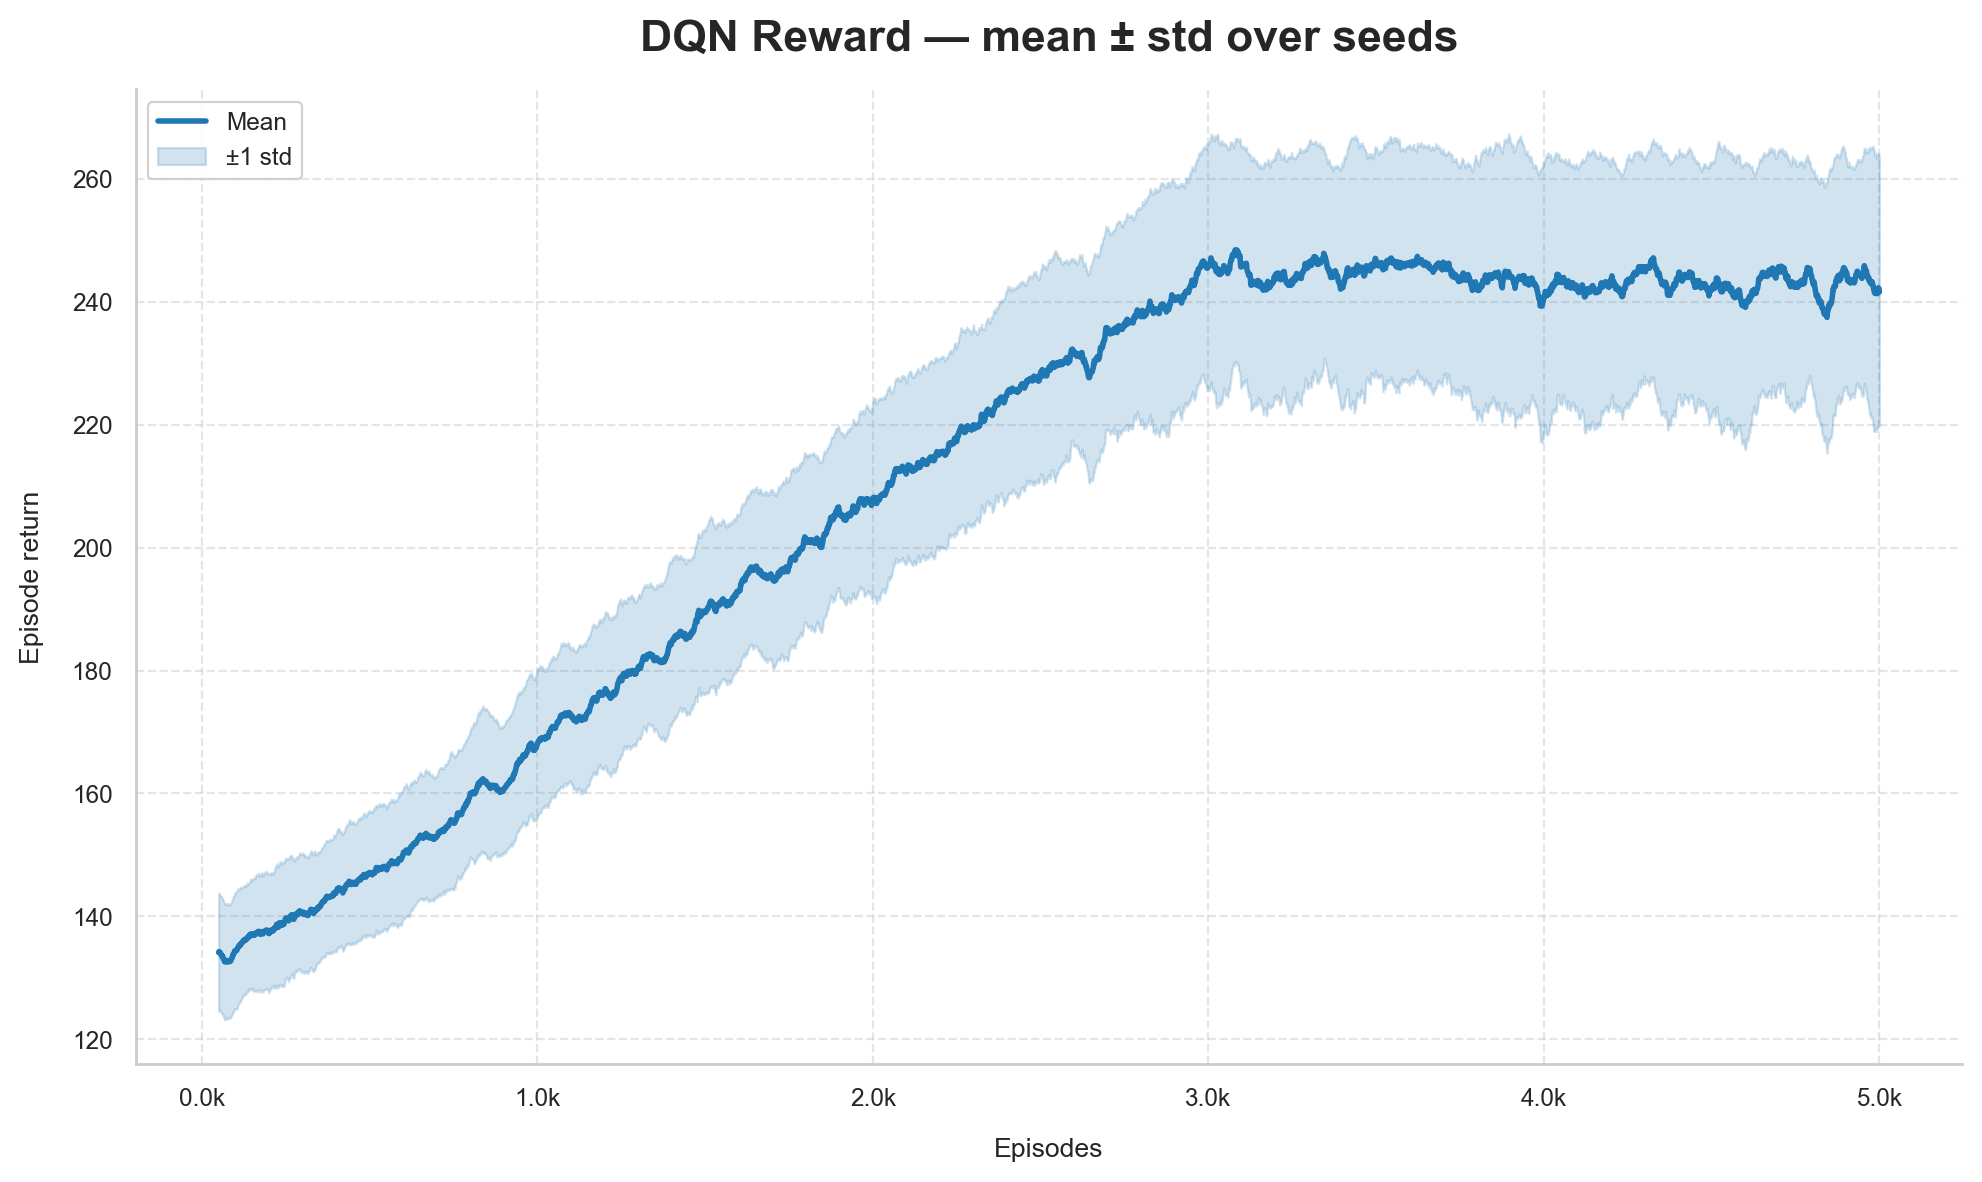

In [8]:
import os, glob, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from matplotlib.ticker import FuncFormatter

LOG_GLOB = "logs/anti_jam_dqn_reward_paper_seed*/monitor.csv"
SMOOTH   = 50   # episodes

def load_monitor_runs(glob_pattern, reward_col="r"):
    paths = sorted(glob.glob(glob_pattern))
    if not paths:
        raise RuntimeError(f"No monitor.csv matches {glob_pattern}")
    runs = []
    for path in paths:
        df = pd.read_csv(path, comment="#")
        if reward_col not in df.columns:
            continue
        rewards = df[reward_col].to_numpy()
        episodes = np.arange(1, len(rewards)+1)
        runs.append((episodes, rewards))
    return runs

def _moving_average(y, w):
    if w <= 1 or w > len(y):
        return y
    k = np.ones(w) / w
    return np.convolve(y, k, mode="valid")

def plot_runs_mean_std(runs, title, ylabel, smooth=50, out_path=None, color="#1f77b4"):
    # align by min length
    L = min(len(v) for _, v in runs)
    steps = runs[0][0][:L]
    Y = np.vstack([v[:L] for _, v in runs])

    mean = Y.mean(axis=0)
    std  = Y.std(axis=0)

    w = min(int(smooth), len(mean))
    if w > 1:
        mean = _moving_average(mean, w)
        std  = _moving_average(std,  w)
        steps = steps[w-1:]

    sns.set_theme(style="whitegrid", context="paper")
    fig, ax = plt.subplots(figsize=(10, 6), dpi=200)
    ax.plot(steps, mean, color=color, lw=2, label="Mean")
    ax.fill_between(steps, mean - std, mean + std, color=color, alpha=0.2, label="±1 std")
    ax.set_title(title, fontsize=16, pad=14, weight="bold")
    ax.set_xlabel("Episodes", labelpad=10)
    ax.set_ylabel(ylabel, labelpad=10)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x/1000:.1f}k"))
    ax.grid(True, ls="--", alpha=0.5)
    sns.despine(ax=ax)
    ax.legend(loc="best", frameon=True, framealpha=0.9, fancybox=True)
    plt.tight_layout()
    if out_path:
        os.makedirs(os.path.dirname(out_path), exist_ok=True)
        plt.savefig(out_path, dpi=300)
    plt.show()

runs = load_monitor_runs(LOG_GLOB)
plot_runs_mean_std(
    runs,
    title="DQN Reward — mean ± std over seeds",
    ylabel="Episode return",
    smooth=SMOOTH,
    out_path="figs/dqn_reward_mean_std.png"
)